<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Tempo_de_Espera_Matchmaking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install simpy

In [2]:
import simpy
import random

# Parâmetros
TOTAL_PLAYERS = 10000
SIMULATION_TIME = 3600  # 1 hora

class MatchmakingSystem:
    def __init__(self, env, active_criteria):
        self.env = env
        self.active_criteria = active_criteria # 1 a 4
        self.queue = []
        self.wait_times = []
        self.abandoned_count = 0

        self.env.process(self.match_engine())

    def is_match(self, p1, p2):
        """Compara dois jogadores baseado em quantos critérios estão ativos."""
        # Critério 1: MMR (diferença máxima de 100 pontos)
        if self.active_criteria >= 1:
            if abs(p1['mmr'] - p2['mmr']) > 100:
                return False

        # Critério 2: Região igual
        if self.active_criteria >= 2:
            if p1['region'] != p2['region']:
                return False

        # Critério 3: Ping aceitável (ambos abaixo de 50ms)
        if self.active_criteria >= 3:
            if p1['ping'] > 50 or p2['ping'] > 50:
                return False

        # Critério 4: Mapa igual
        if self.active_criteria >= 4:
            if p1['map'] != p2['map']:
                return False

        return True

    def match_engine(self):
        """Motor que roda a cada 1 segundo procurando pares (x1) na fila."""
        while True:
            yield self.env.timeout(1)

            # Tenta formar pares enquanto houver pelo menos 2 pessoas na fila
            i = 0
            while i < len(self.queue) - 1:
                p1 = self.queue[i]
                matched = False

                # Procura um par para p1 no resto da fila
                for j in range(i + 1, len(self.queue)):
                    p2 = self.queue[j]

                    if self.is_match(p1, p2):
                        # Match encontrado!
                        current_time = self.env.now
                        self.wait_times.append(current_time - p1['arrival_time'])
                        self.wait_times.append(current_time - p2['arrival_time'])

                        p1['matched'] = True
                        p2['matched'] = True

                        # Remove os dois da fila (o de maior índice primeiro para não bugar a lista)
                        self.queue.pop(j)
                        self.queue.pop(i)

                        matched = True
                        break # Volta para o while principal para tentar parear o próximo

                if not matched:
                    i += 1 # Se não achou par, avança para o próximo jogador da fila

def player_behavior(env, mm_system, player):
    """Paciência do jogador (Normal: 30s média, 5s desvio)."""
    patience = max(1, random.gauss(30, 5))
    yield env.timeout(patience)

    if not player['matched']:
        if player in mm_system.queue:
            mm_system.queue.remove(player)
            mm_system.abandoned_count += 1

def generate_players(env, mm_system):
    """Gera 10.000 jogadores com características únicas."""
    arrival_times = [random.uniform(0, SIMULATION_TIME) for _ in range(TOTAL_PLAYERS)]
    arrival_times.sort()

    last_time = 0
    for arrival in arrival_times:
        yield env.timeout(arrival - last_time)
        last_time = arrival

        # Criação do "RG" do jogador
        player = {
            'arrival_time': env.now,
            'matched': False,
            'mmr': random.gauss(1500, 200),        # Maioria em torno de 1500
            'region': random.choice(['A', 'B', 'C']),
            'ping': random.uniform(10, 100),       # Ping de 10 a 100
            'map': random.choice(['Mapa 1', 'Mapa 2', 'Mapa 3'])
        }

        mm_system.queue.append(player)
        env.process(player_behavior(env, mm_system, player))

# === EXECUTANDO O EXPERIMENTO ===
print("Simulação x1: Procurando partida com Atributos Reais...\n")

for criteria in [1, 2, 3, 4]:
    random.seed(42)
    env = simpy.Environment()
    mm = MatchmakingSystem(env, active_criteria=criteria)
    env.process(generate_players(env, mm))
    env.run(until=SIMULATION_TIME + 60)

    avg_wait = sum(mm.wait_times) / len(mm.wait_times) if mm.wait_times else 0
    match_rate = (len(mm.wait_times) / TOTAL_PLAYERS) * 100

    print(f"[{criteria} Critérios Ativos]")
    print(f" ➔ Tempo Médio de Espera: {avg_wait:.2f}s")
    print(f" ➔ Desistências: {mm.abandoned_count}")
    print(f" ➔ Partidas encontradas: {len(mm.wait_times) // 2} ({match_rate:.1f}% dos jogadores)\n")

Simulação x1: Procurando partida com Atributos Reais...

[1 Critérios Ativos]
 ➔ Tempo Médio de Espera: 1.47s
 ➔ Desistências: 70
 ➔ Partidas encontradas: 4965 (99.3% dos jogadores)

[2 Critérios Ativos]
 ➔ Tempo Médio de Espera: 2.93s
 ➔ Desistências: 224
 ➔ Partidas encontradas: 4888 (97.8% dos jogadores)

[3 Critérios Ativos]
 ➔ Tempo Médio de Espera: 4.74s
 ➔ Desistências: 5936
 ➔ Partidas encontradas: 2032 (40.6% dos jogadores)

[4 Critérios Ativos]
 ➔ Tempo Médio de Espera: 6.82s
 ➔ Desistências: 6760
 ➔ Partidas encontradas: 1620 (32.4% dos jogadores)



Rodando simulações e preparando dados para os histogramas...

[1 Critérios] Média: 1.47s | Partidas: 4965
[2 Critérios] Média: 2.93s | Partidas: 4888
[3 Critérios] Média: 4.74s | Partidas: 2032
[4 Critérios] Média: 6.82s | Partidas: 1620


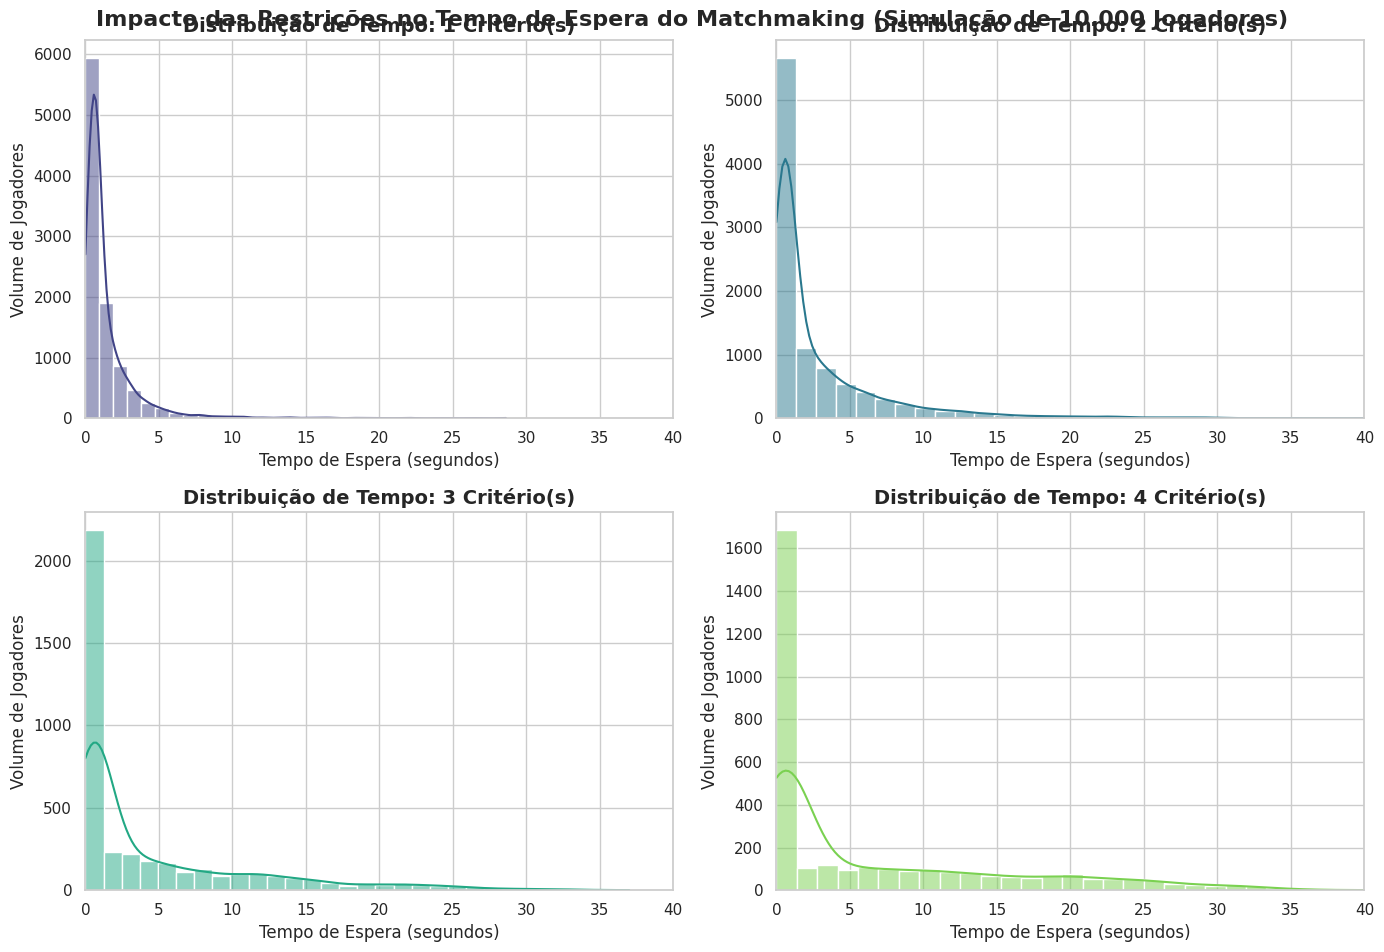

In [3]:

import simpy
import random
import matplotlib.pyplot as plt
import seaborn as sns

# [Cole as classes MatchmakingSystem e as funções player_behavior e generate_players do código anterior aqui]

# === EXECUTANDO O EXPERIMENTO E COLETANDO DADOS ===
print("Rodando simulações e preparando dados para os histogramas...\n")

# Dicionário para armazenar a lista de tempos de espera de cada cenário
resultados_espera = {}

for criteria in [1, 2, 3, 4]:
    random.seed(42)
    env = simpy.Environment()
    mm = MatchmakingSystem(env, active_criteria=criteria)
    env.process(generate_players(env, mm))
    env.run(until=SIMULATION_TIME + 60)

    # Salva todos os tempos individuais de quem conseguiu jogar
    resultados_espera[criteria] = mm.wait_times

    avg_wait = sum(mm.wait_times) / len(mm.wait_times) if mm.wait_times else 0
    print(f"[{criteria} Critérios] Média: {avg_wait:.2f}s | Partidas: {len(mm.wait_times) // 2}")

# === PLOTANDO OS HISTOGRAMAS (STORYTELLING VISUAL) ===
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# Paleta Viridis para clareza e contraste
colors = sns.color_palette("viridis", 4)

for i, criteria in enumerate([1, 2, 3, 4]):
    plt.subplot(2, 2, i + 1)

    # Histograma com a curva de densidade (KDE) para ver bem o formato
    sns.histplot(resultados_espera[criteria], bins=30, kde=True, color=colors[i], edgecolor="white")

    plt.title(f'Distribuição de Tempo: {criteria} Critério(s)', fontsize=14, fontweight='bold')
    plt.xlabel('Tempo de Espera (segundos)', fontsize=12)
    plt.ylabel('Volume de Jogadores', fontsize=12)

    # Mantendo o eixo X fixo entre 0 e 40 segundos para a comparação ser justa e visualmente imediata
    plt.xlim(0, 40)

plt.suptitle("Impacto das Restrições no Tempo de Espera do Matchmaking (Simulação de 10.000 Jogadores)", fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout()
plt.show()

Rodando simulações com paciência curta (15s média)...

[1 Critério(s)] Abandono: 1.7%
[2 Critério(s)] Abandono: 7.3%
[3 Critério(s)] Abandono: 64.8%
[4 Critério(s)] Abandono: 76.1%


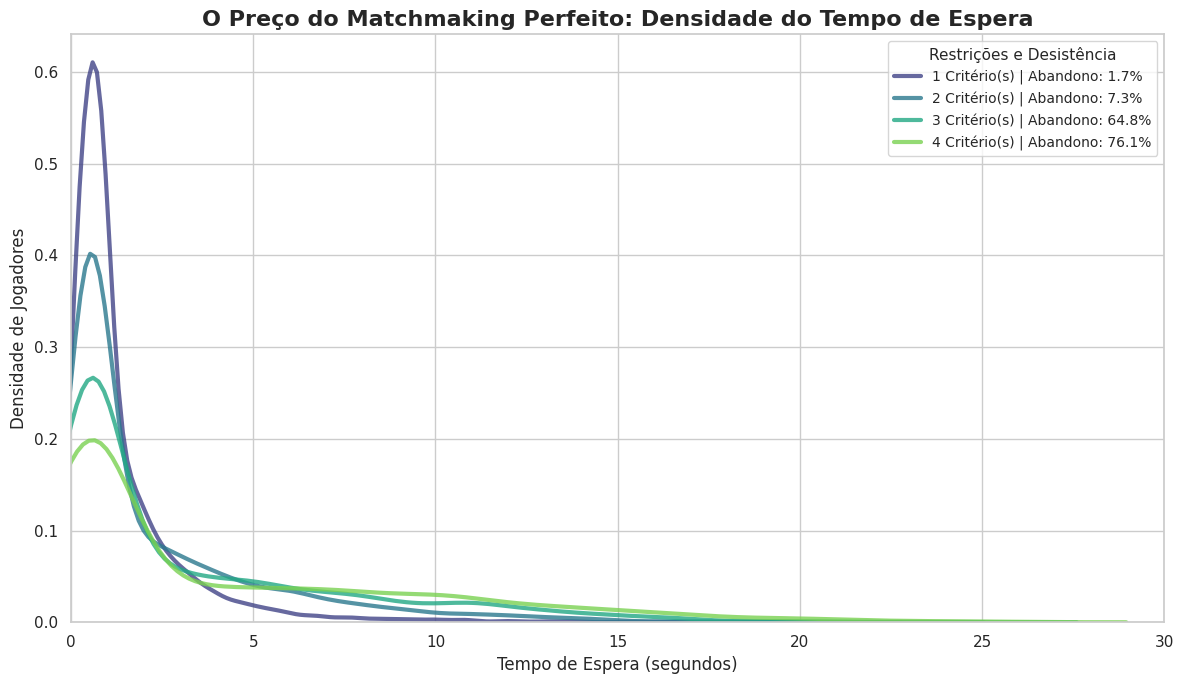

In [8]:
import simpy
import random
import matplotlib.pyplot as plt
import seaborn as sns

# Parâmetros
TOTAL_PLAYERS = 10000
SIMULATION_TIME = 3600  # 1 hora

class MatchmakingSystem:
    def __init__(self, env, active_criteria):
        self.env = env
        self.active_criteria = active_criteria
        self.queue = []
        self.wait_times = []
        self.abandoned_count = 0

        self.env.process(self.match_engine())

    def is_match(self, p1, p2):
        if self.active_criteria >= 1:
            if abs(p1['mmr'] - p2['mmr']) > 100: return False
        if self.active_criteria >= 2:
            if p1['region'] != p2['region']: return False
        if self.active_criteria >= 3:
            if p1['ping'] > 50 or p2['ping'] > 50: return False
        if self.active_criteria >= 4:
            if p1['map'] != p2['map']: return False
        return True

    def match_engine(self):
        while True:
            yield self.env.timeout(1)
            i = 0
            while i < len(self.queue) - 1:
                p1 = self.queue[i]
                matched = False
                for j in range(i + 1, len(self.queue)):
                    p2 = self.queue[j]
                    if self.is_match(p1, p2):
                        current_time = self.env.now
                        self.wait_times.append(current_time - p1['arrival_time'])
                        self.wait_times.append(current_time - p2['arrival_time'])
                        p1['matched'], p2['matched'] = True, True
                        self.queue.pop(j)
                        self.queue.pop(i)
                        matched = True
                        break
                if not matched:
                    i += 1

def player_behavior(env, mm_system, player):
    # Nova paciência: Média de 15s, desvio de 5s
    patience = max(1, random.gauss(15, 5))
    yield env.timeout(patience)

    if not player['matched']:
        if player in mm_system.queue:
            mm_system.queue.remove(player)
            mm_system.abandoned_count += 1

def generate_players(env, mm_system):
    arrival_times = [random.uniform(0, SIMULATION_TIME) for _ in range(TOTAL_PLAYERS)]
    arrival_times.sort()

    last_time = 0
    for arrival in arrival_times:
        yield env.timeout(arrival - last_time)
        last_time = arrival

        player = {
            'arrival_time': env.now,
            'matched': False,
            'mmr': random.gauss(1500, 200),
            'region': random.choice(['A', 'B', 'C']),
            'ping': random.uniform(10, 100),
            'map': random.choice(['Mapa 1', 'Mapa 2', 'Mapa 3'])
        }
        mm_system.queue.append(player)
        env.process(player_behavior(env, mm_system, player))

# === EXECUTANDO O EXPERIMENTO ===
print("Rodando simulações com paciência curta (15s média)...\n")

resultados_espera = {}
taxas_abandono = {}

for criteria in [1, 2, 3, 4]:
    random.seed(42)
    env = simpy.Environment()
    mm = MatchmakingSystem(env, active_criteria=criteria)
    env.process(generate_players(env, mm))
    env.run(until=SIMULATION_TIME + 60)

    resultados_espera[criteria] = mm.wait_times
    taxas_abandono[criteria] = (mm.abandoned_count / TOTAL_PLAYERS) * 100
    print(f"[{criteria} Critério(s)] Abandono: {taxas_abandono[criteria]:.1f}%")

# === PLOTANDO O GRÁFICO UNIFICADO (KDE) ===
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# Mantendo a paleta Viridis para um degradê visual claro das restrições
colors = sns.color_palette("viridis", 4)

for i, criteria in enumerate([1, 2, 3, 4]):
    sns.kdeplot(
        resultados_espera[criteria],
        color=colors[i],
        alpha=0.8,
        linewidth=3,
        label=f'{criteria} Critério(s) | Abandono: {taxas_abandono[criteria]:.1f}%'
    )

plt.title("O Preço do Matchmaking Perfeito: Densidade do Tempo de Espera", fontsize=16, fontweight='bold')
plt.xlabel("Tempo de Espera (segundos)", fontsize=12)
plt.ylabel("Densidade de Jogadores", fontsize=12)
plt.xlim(0, 30) # Travado nos 30s para evidenciar o corte da paciência
plt.legend(title="Restrições e Desistência", fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()